# Hotel Booking Cancellation Prediction

predict whether a hotel booking is canceled (`is_canceled`, binary classification).

Workflow: problem definition → imports → load → understand → quality → EDA → cleaning → feature engineering → split → preprocessing → imbalance → feature selection  → baseline → models → CV → tuning → final test → error analysis → comparison → importance → save model → conclusion → future work.


# Problem Definition

**Business problem.** Bookings canceled later leave rooms unsold and hurt revenue and capacity planning. The hotel wants to flag risky bookings at booking time.

**ML problem.** Supervised binary classification: input = booking attributes known at booking time; output = `is_canceled` (0 = kept, 1 = canceled).


#  Import Libraries


In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate,
    GridSearchCV, RandomizedSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler, OneHotEncoder
)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.feature_selection import SelectFromModel
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report
)

from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline






# Plot style for consistent, labelled charts
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100



#  Load Dataset



In [2]:
DATA_PATH = "hotel_bookings.csv"
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join("C:\\ML test", "hotel_bookings.csv")

df = pd.read_csv(DATA_PATH)

print(df.shape)

(119390, 32)


#  Data Understanding



In [3]:
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
print()

df.head()

Rows: 119390 | Columns: 32



,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [4]:
df.tail()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,...,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,2017-09-07


In [5]:
df.dtypes.value_counts()


int64      16
str        12
float64     4
Name: count, dtype: int64

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


## Feature Understanding

| Feature | Meaning | Type |
|---------|---------|------|
| `hotel` | Resort or City hotel | categorical |
| `is_canceled` | 0 = not canceled, 1 = canceled (**target**) | binary |
| `lead_time` | Days between booking and arrival | numerical |
| `arrival_date_year` | Year of arrival | numerical |
| `arrival_date_month` | Month of arrival | categorical |
| `arrival_date_week_number` | Week number of arrival (1 to 53 weeks)| numerical |
| `arrival_date_day_of_month` | Day of arrival | numerical |
| `stays_in_weekend_nights` | Weekend nights booked | numerical |
| `stays_in_week_nights` | Week nights booked | numerical |
| `adults` / `children` / `babies` | Number of guests | numerical |
| `meal` | Meal plan chosen | categorical |
| `country` | Country of origin (ISO code) | categorical |
| `market_segment` | Booking segment | categorical |
| `distribution_channel` | Channel used | categorical |
| `is_repeated_guest` | 1 if returning guest | binary |
| `previous_cancellations` | Past cancellations | numerical |
| `previous_bookings_not_canceled` | Past kept bookings | numerical |
| `reserved_room_type` / `assigned_room_type` | Room codes | categorical |
| `booking_changes` | Number of booking changes | numerical |
| `deposit_type` | No Deposit / Refundable / Non Refund | categorical |
| `agent` | Travel agency ID (NaN = direct) | numerical ID |
| `company` | Company ID (very sparse) | numerical ID |
| `days_in_waiting_list` | Days on waiting list | numerical |
| `customer_type` | Transient / Group / Contract ... | categorical |
| `adr` | Average Daily Rate (price) | numerical |
| `required_car_parking_spaces` | Parking spaces requested | numerical |
| `total_of_special_requests` | Number of special requests | numerical |
| `reservation_status` | Check-Out / Canceled / No-Show (**leakage**) | categorical |
| `reservation_status_date` | Date of status change (**leakage**) | date |



#  Data Quality Assessment



##  Missing Values



In [8]:
df.isnull().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [9]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing.to_string())
print()

company     112593
agent        16340
country        488
children         4



##  Duplicate Records



In [10]:

print("duplicated rows:", df.duplicated().sum())

duplicated rows: 31994


In [11]:
# Take the duplicated group and check what varies
dup_mask = df.duplicated(keep=False)
dup_rows = df[dup_mask].copy()

# Group them by all columns and count group sizes
group_sizes = dup_rows.groupby(dup_rows.columns.tolist(), dropna=False).size()
print(f"How many duplicate groups? {len(group_sizes):,}")
print(f"Largest group: {group_sizes.max()}")
print(f"Median group size: {group_sizes.median()}")
print("\nGroup size distribution:")
print(group_sizes.value_counts().sort_index().head(20))

How many duplicate groups? 8,171
Largest group: 180
Median group size: 2.0

Group size distribution:
2     5034
3      969
4      497
5      275
6      171
7      115
8      103
9       93
10     123
11      60
12      47
13      36
14      36
15      64
16      32
17      33
18      28
19      35
20      97
21       9
Name: count, dtype: int64


##  Invalid Values



In [12]:

print("Bookings with adults Count 0 :", (df["adults"] == 0).sum())

Bookings with adults Count 0 : 403


In [13]:
#negative ADR
neg = df[df["adr"] < 0]
print(" Negative ADR Count:", len(neg))


 Negative ADR Count: 1


In [14]:
# numeric Values range checks
for col in ["lead_time", "adr", "adults", "children", "babies",
            "stays_in_week_nights", "stays_in_weekend_nights"]:
    print(f"{col:>28}: min={df[col].min():.2f}  max={df[col].max():.2f}")

                   lead_time: min=0.00  max=737.00
                         adr: min=-6.38  max=5400.00
                      adults: min=0.00  max=55.00
                    children: min=0.00  max=10.00
                      babies: min=0.00  max=10.00
        stays_in_week_nights: min=0.00  max=50.00
     stays_in_weekend_nights: min=0.00  max=19.00


##  Outliers & Noise



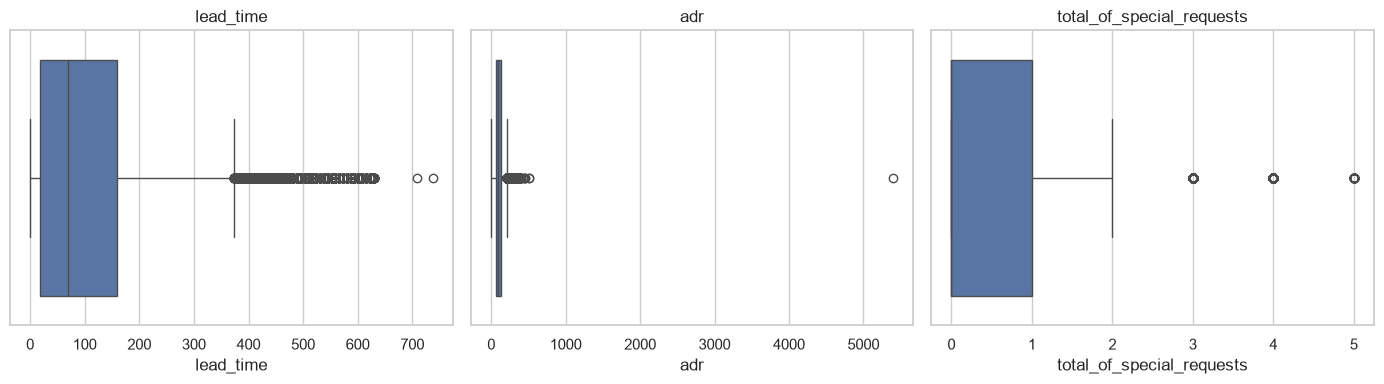

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["lead_time", "adr", "total_of_special_requests"]):
    sns.boxplot(data=df, x=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

##  Inconsistent Categories

Check categorical columns for placeholder categories and count the levels of each column.

In [16]:
# Categorical columns and it's unique values 
cat_cols = df.select_dtypes(include=["object", "string", "category"]).columns.tolist()
for c in cat_cols:
    vc = df[c].value_counts(dropna=False)
    print(f"--- {c} | n_unique={vc.size} ---")
    print(vc.head(10).to_string())
    print()

--- hotel | n_unique=2 ---
hotel
City Hotel      79330
Resort Hotel    40060

--- arrival_date_month | n_unique=12 ---
arrival_date_month
August       13877
July         12661
May          11791
October      11160
April        11089
June         10939
September    10508
March         9794
February      8068
November      6794

--- meal | n_unique=5 ---
meal
BB           92310
HB           14463
SC           10650
Undefined     1169
FB             798

--- country | n_unique=178 ---
country
PRT    48590
GBR    12129
FRA    10415
ESP     8568
DEU     7287
ITA     3766
IRL     3375
BEL     2342
BRA     2224
NLD     2104

--- market_segment | n_unique=8 ---
market_segment
Online TA        56477
Offline TA/TO    24219
Groups           19811
Direct           12606
Corporate         5295
Complementary      743
Aviation           237
Undefined            2

--- distribution_channel | n_unique=5 ---
distribution_channel
TA/TO        97870
Direct       14645
Corporate     6677
GDS            193

##   Data Leakage columns



In [17]:

ct = pd.crosstab(df["reservation_status"], df["is_canceled"])
print(ct.to_string())


is_canceled             0      1
reservation_status              
Canceled                0  43017
Check-Out           75166      0
No-Show                 0   1207


##  Data Quality Summary Table

| Problem | Found? | Evidence | Action |
|---|---|---|---|
| Missing values | Yes | children 4, country 488, agent 16340, company 112593 | Drop company; impute the rest on training data |
| Duplicates | Yes | 31994 rows | Remove  |
| Invalid adults | Yes | 403 rows `adults == 0` | Remove (domain rule: ≥ 1 adult) |
| Negative ADR | Yes | 1 row `adr = -6.38` | Convert to NaN → imputed |
| Outliers | Yes | heavy tails in lead_time / adr / requests | Keep (legitimate) |
| Inconsistent labels | Yes | `Undefined` in 3 categoricals | Keep as own category |
| Data leakage | Yes | status columns predict the target exactly | Remove the 2 columns |
| Identifier features | Yes | company (94% missing), agent (ID-like) | Drop company; `agent` → `has_agent` |

#  Exploratory Data Analysis (EDA)



##  Target Analysis

=== is_canceled distribution ===
is_canceled
0    75166
1    44224
Name: count, dtype: int64

is_canceled
0    62.958372
1    37.041628
Name: proportion, dtype: float64


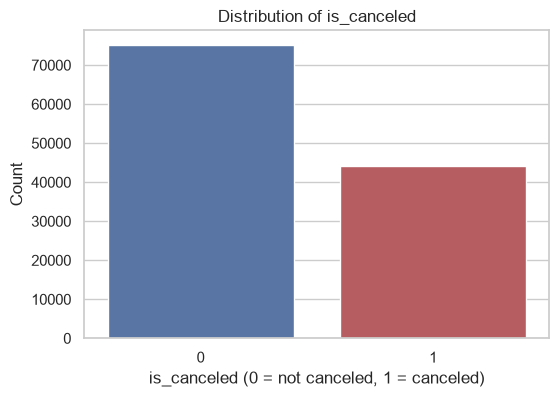

In [17]:
print("=== is_canceled distribution ===")
print(df["is_canceled"].value_counts())
print()
print(df["is_canceled"].value_counts(normalize=True) * 100)

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="is_canceled", palette=["#4c72b0", "#c44e52"])
plt.title("Distribution of is_canceled")
plt.xlabel("is_canceled (0 = not canceled, 1 = canceled)")
plt.ylabel("Count")
plt.show()



Distributions of numeric variables and counts of categorical variables.

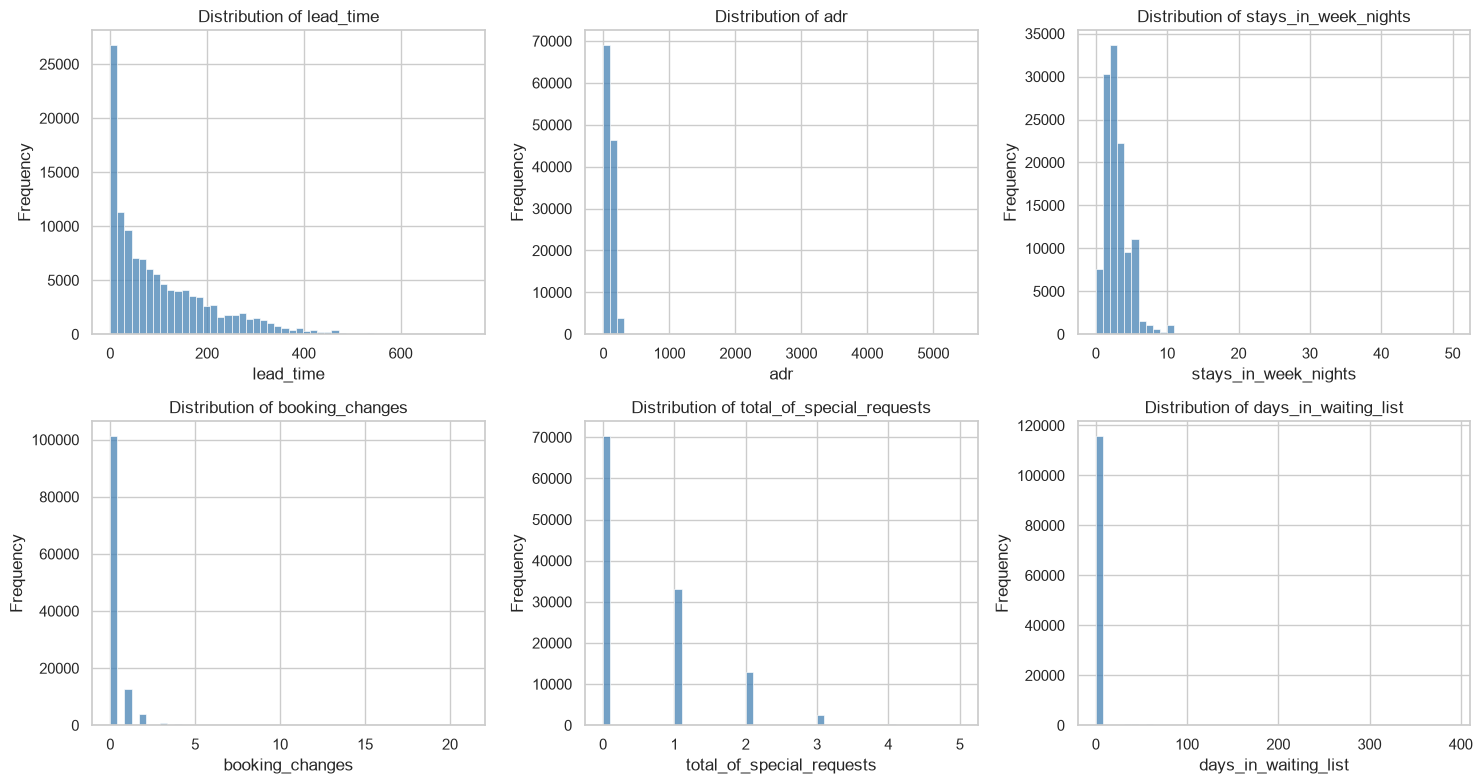

In [18]:
num_cols = ["lead_time", "adr", "stays_in_week_nights", "booking_changes",
             "total_of_special_requests", "days_in_waiting_list"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(data=df, x=col, bins=50, color="steelblue", ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")
plt.tight_layout()
plt.show()

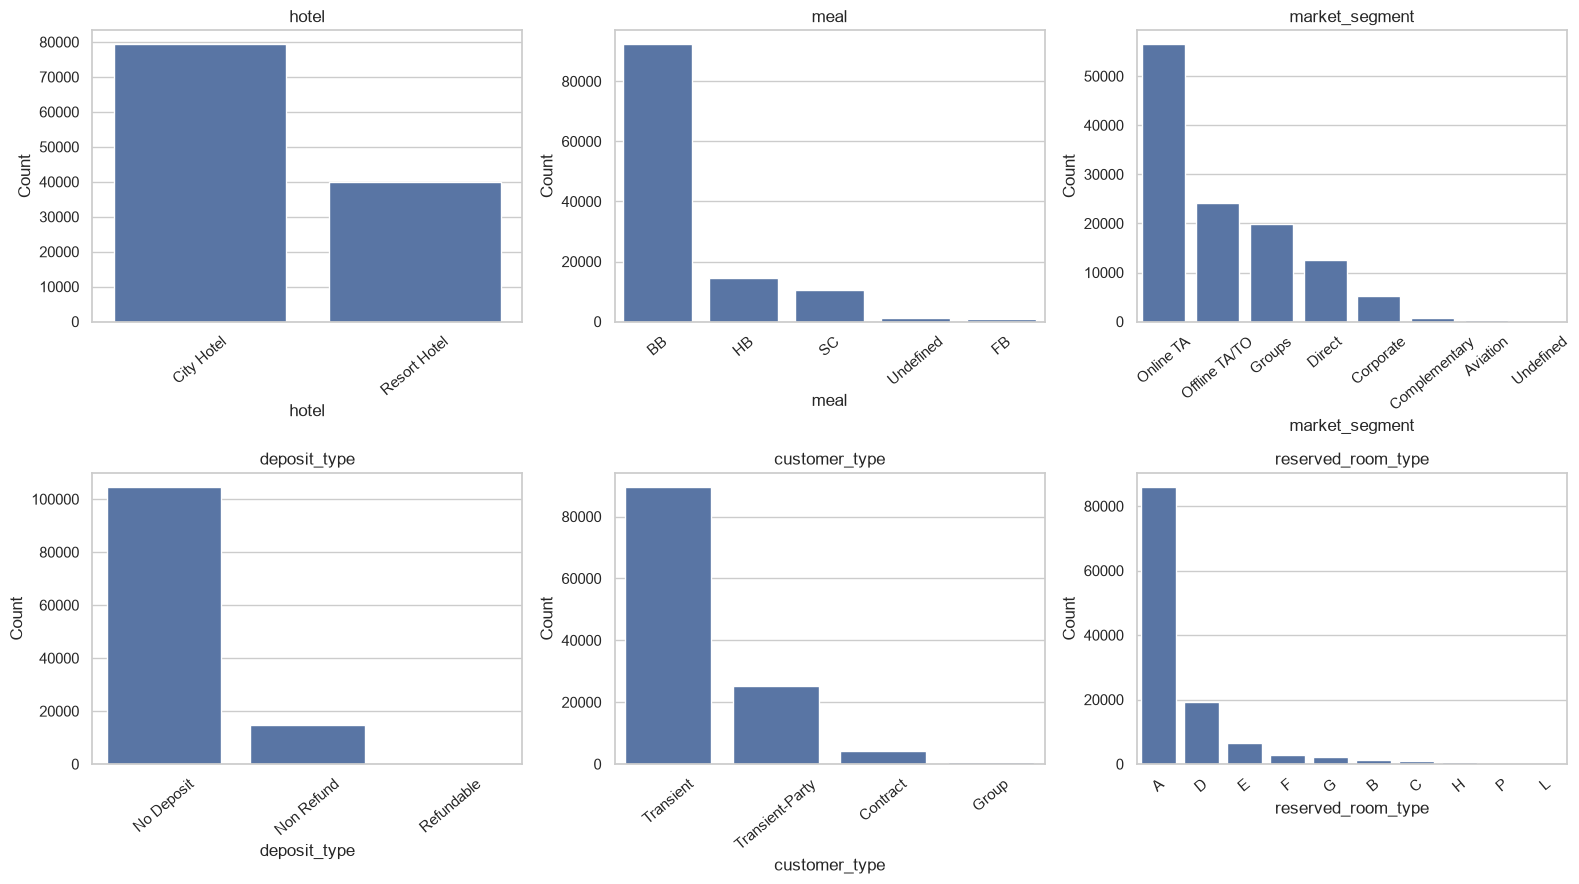

In [19]:
cat_cols_show = ["hotel", "meal", "market_segment", "deposit_type",
                 "customer_type", "reserved_room_type"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.ravel(), cat_cols_show):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, color="#4c72b0", ax=ax)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=40)
plt.tight_layout()
plt.show()

##  features vs target

Cancellation rate per category, plus numeric feature distributions split by target.

In [20]:
def cancellation_rate_by(col):
    rate = df.groupby(col)["is_canceled"].mean().sort_values(ascending=False)
    count = df.groupby(col)["is_canceled"].count().reindex(rate.index)
    res = pd.DataFrame({"cancellation_rate": rate, "n_bookings": count})
    return res

for col in ["hotel", "market_segment", "deposit_type", "customer_type"]:
    tab = cancellation_rate_by(col)
    print(f"=== Cancellation rate by {col} ===")
    print(round(tab, 3).to_string())
    print()

=== Cancellation rate by hotel ===
              cancellation_rate  n_bookings
hotel                                      
City Hotel                0.417       79330
Resort Hotel              0.278       40060

=== Cancellation rate by market_segment ===
                cancellation_rate  n_bookings
market_segment                               
Undefined                   1.000           2
Groups                      0.611       19811
Online TA                   0.367       56477
Offline TA/TO               0.343       24219
Aviation                    0.219         237
Corporate                   0.187        5295
Direct                      0.153       12606
Complementary               0.131         743

=== Cancellation rate by deposit_type ===
              cancellation_rate  n_bookings
deposit_type                               
Non Refund                0.994       14587
No Deposit                0.284      104641
Refundable                0.222         162

=== Cancellation rat

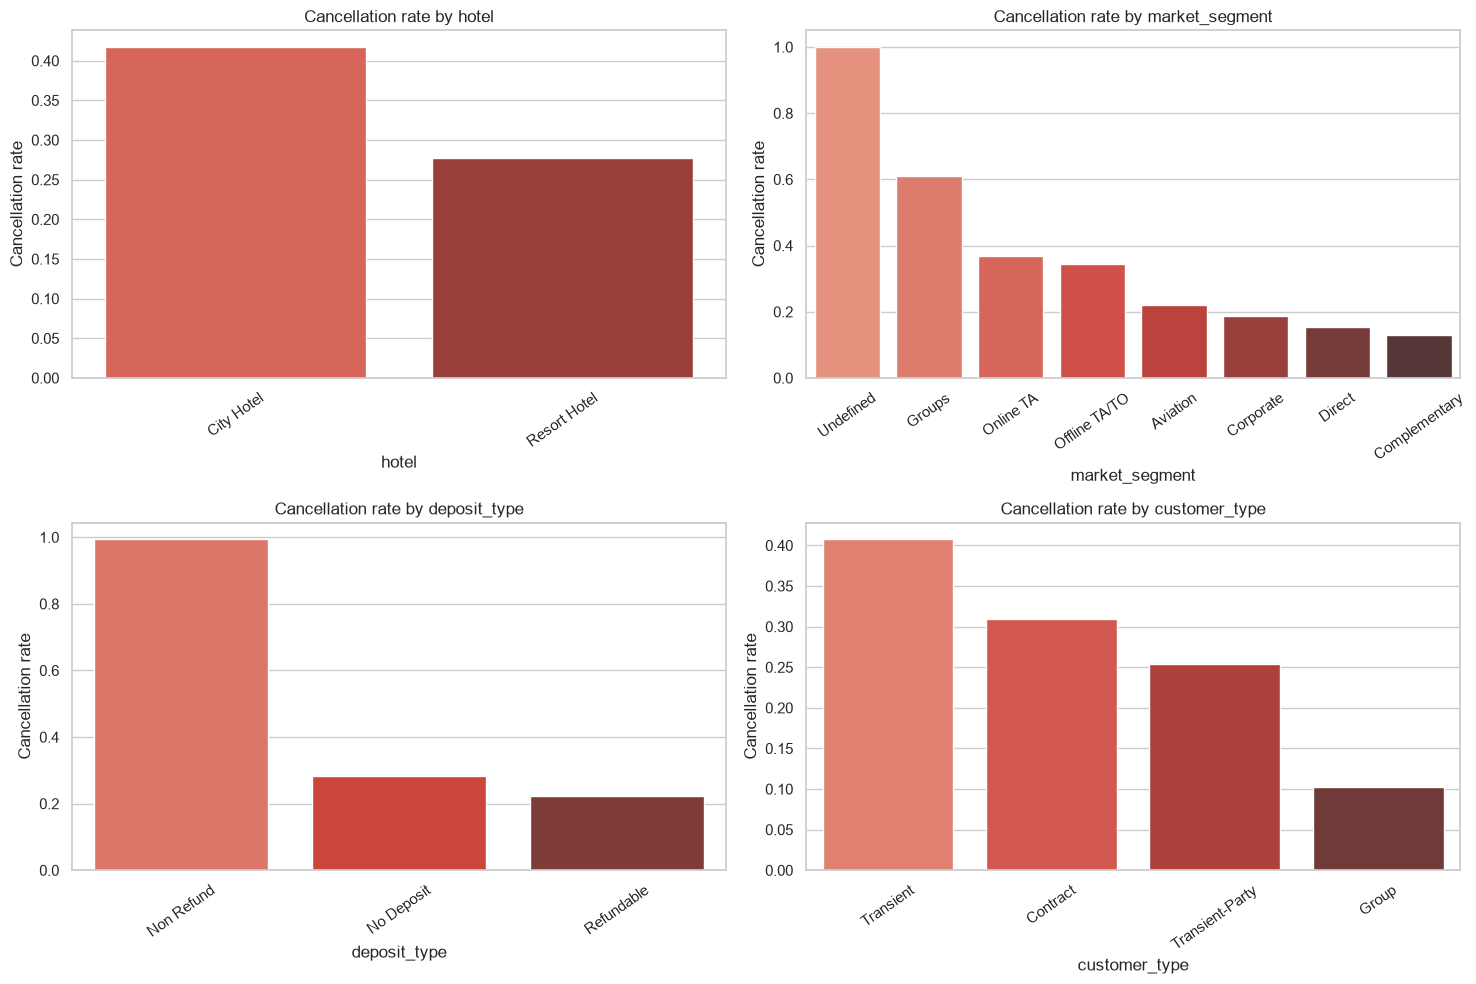

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, col in zip(axes.ravel(), ["hotel", "market_segment", "deposit_type", "customer_type"]):
    tab = cancellation_rate_by(col)
    sns.barplot(x=tab.index, y="cancellation_rate", data=tab.reset_index(), ax=ax, palette="Reds_d")
    ax.set_title(f"Cancellation rate by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Cancellation rate")
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

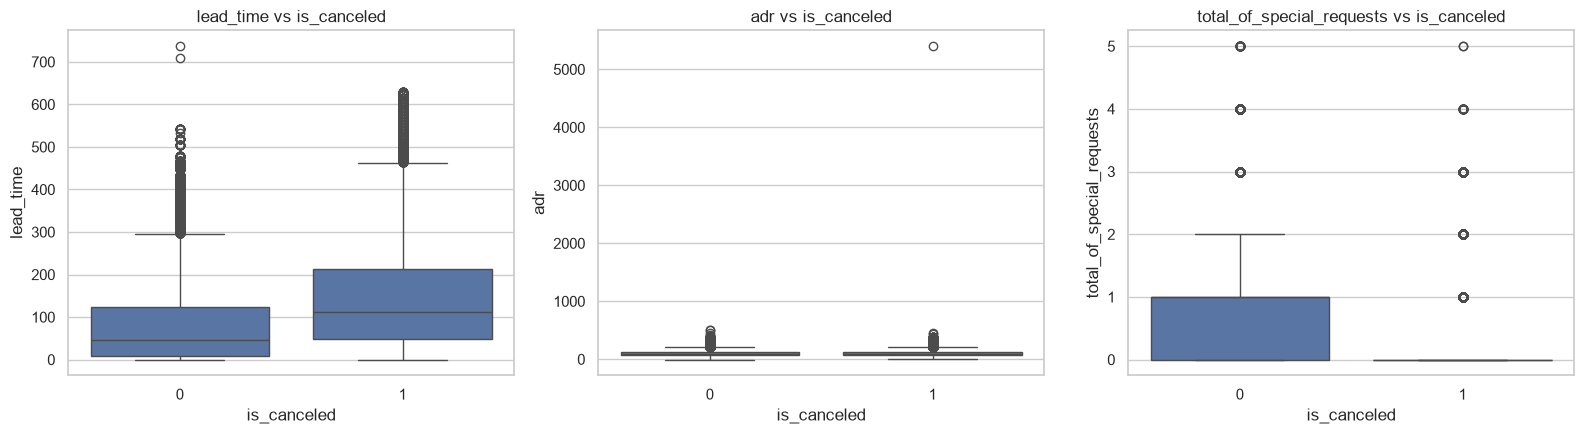

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ["lead_time", "adr", "total_of_special_requests"]):
    sns.boxplot(data=df, x="is_canceled", y=col, ax=ax)
    ax.set_title(f"{col} vs is_canceled")
    ax.set_xlabel("is_canceled")
    ax.set_ylabel(col)
plt.tight_layout()
plt.show()

## Correlation Analysis 



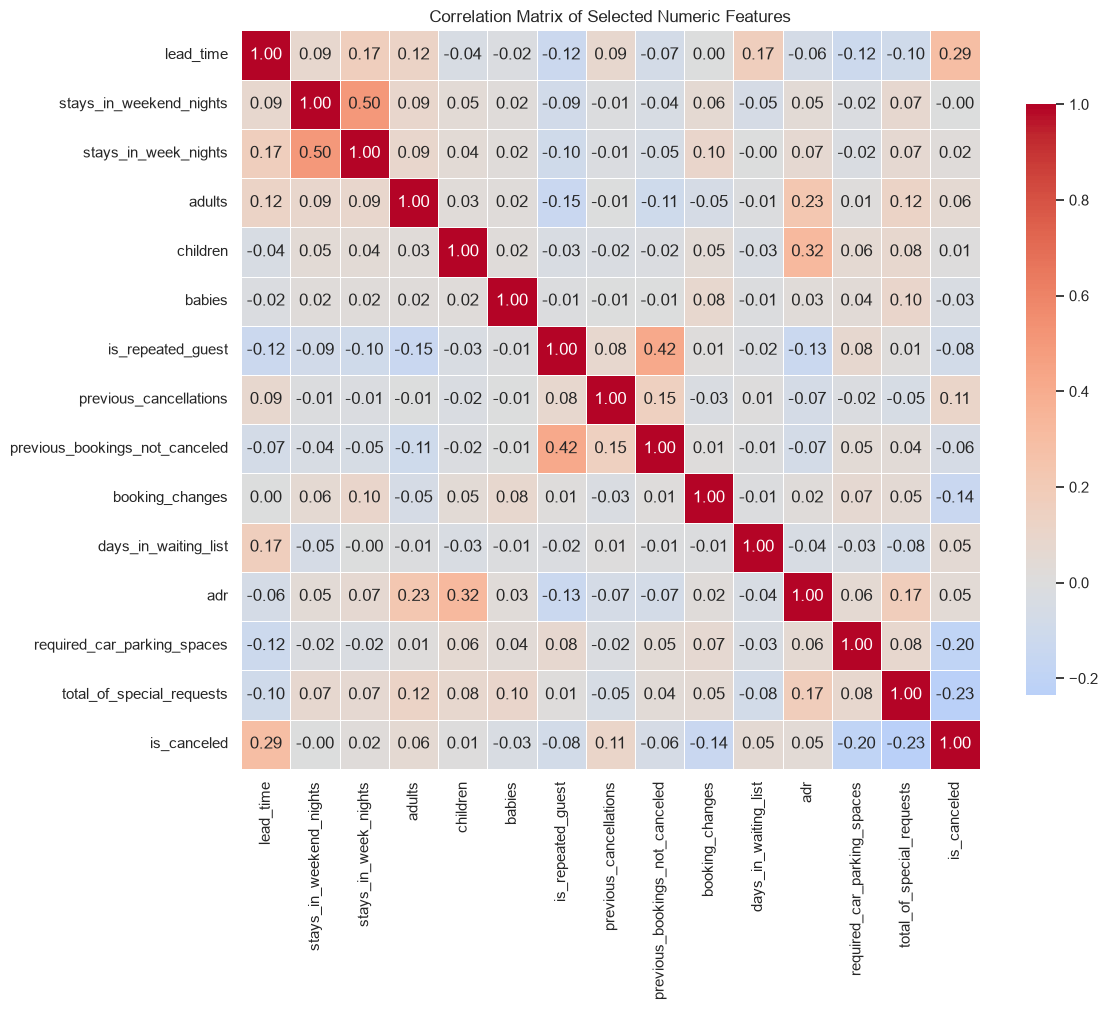

=== Absolute correlation with target (univariate glance) ===
lead_time                         0.293
total_of_special_requests         0.235
required_car_parking_spaces       0.195
booking_changes                   0.144
previous_cancellations            0.110
is_repeated_guest                 0.085
adults                            0.060
previous_bookings_not_canceled    0.057
days_in_waiting_list              0.054
adr                               0.048
babies                            0.032
stays_in_week_nights              0.025
children                          0.005
stays_in_weekend_nights           0.002


In [23]:
corr_cols = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights",
               "adults", "children", "babies", "is_repeated_guest",
               "previous_cancellations", "previous_bookings_not_canceled",
               "booking_changes", "days_in_waiting_list", "adr",
               "required_car_parking_spaces", "total_of_special_requests", "is_canceled"]

corr = df[corr_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            linewidths=0.5, square=True, cbar_kws={"shrink": 0.8})
plt.title("Correlation Matrix of Selected Numeric Features")
plt.tight_layout()
plt.show()

top = corr["is_canceled"].drop("is_canceled").abs().sort_values(ascending=False)
print("=== Absolute correlation with target (univariate glance) ===")
print(round(top, 3).to_string())

 lead_time vs adr 


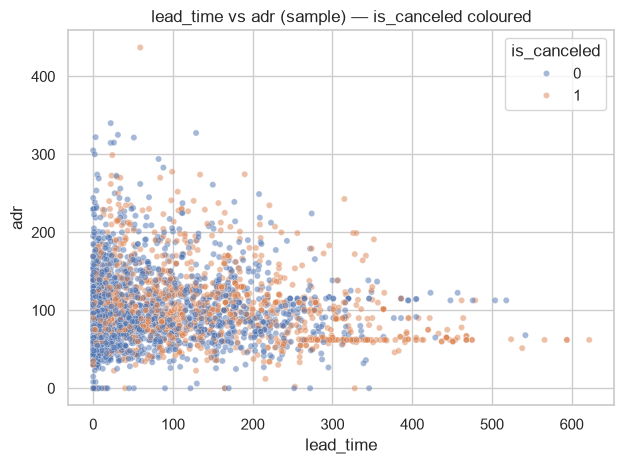

In [24]:
print(" lead_time vs adr ")
sample = df.sample(3000, random_state=42)
sns.scatterplot(data=sample, x="lead_time", y="adr", hue="is_canceled", alpha=0.5, s=20)
plt.title("lead_time vs adr (sample) — is_canceled coloured")
plt.xlabel("lead_time")
plt.ylabel("adr")
plt.tight_layout()
plt.show()

# Preprocessing

##  Data Cleaning



##  Remove Duplicate Records



In [25]:
df_model = df.copy()
print("Rows before cleaning:", df_model.shape[0])

n_dups_before = df_model.duplicated().sum()
print("Duplicate rows before removal:", n_dups_before)

df_model = df_model.drop_duplicates().reset_index(drop=True)

print()
print("Rows after duplicate removal:", df_model.shape[0])
print("Duplicate rows after removal:", df_model.duplicated().sum())
print("Shape:", df_model.shape)

Rows before cleaning: 119390
Duplicate rows before removal: 31994

Rows after duplicate removal: 87396
Duplicate rows after removal: 0
Shape: (87396, 32)


**Why we removed duplicates:** 31,994 rows were exact matches across all 32 columns, forming 8,171 duplicate groups (median group size = 2, largest = 180). It's highly unlikely that many independent bookings would match on every field by coincidence, so these are treated as duplicate records and removed **before** the train/test split — this also prevents an identical row from landing in both train and test, which would otherwise inflate test performance.

##  Invalid Values 

###  Adults == 0
Business assumption: *a valid booking requires at least one adult.* Rows with `adults <= 0` are removed.

In [26]:
n_invalid_adults = (df_model["adults"] <= 0).sum()
print("Rows with adults <= 0 :", n_invalid_adults)

df_model = df_model[df_model["adults"] > 0].reset_index(drop=True)
print("Rows after removing invalid adults:", df_model.shape[0])

Rows with adults <= 0 : 385
Rows after removing invalid adults: 87011


###  Negative ADR


In [27]:
n_neg_adr = (df_model["adr"] < 0).sum()
print("Rows with negative adr detected:", n_neg_adr)

df_model.loc[df_model["adr"] < 0, "adr"] = np.nan
print("Negative adr now converted to NaN.")
print("Remaining negative adr values:", (df_model["adr"] < 0).sum())

Rows with negative adr detected: 1
Negative adr now converted to NaN.
Remaining negative adr values: 0


##  Leakage Removal



In [28]:
leak_columns = ["reservation_status", "reservation_status_date"]
leak_present = [c for c in leak_columns if c in df_model.columns]
print("Leakage columns:", leak_present)

df_model = df_model.drop(columns=leak_present)


print()
print("Columns now:", df_model.shape[1])
print(df_model.columns.tolist())

Leakage columns: ['reservation_status', 'reservation_status_date']

Columns now: 30
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']


##  Identifier-like Features



In [29]:
print("Missing rates (percent):")
print(round(df_model[["company", "agent"]].isna().mean() * 100, 2).to_string())
print()

df_model["has_agent"] = df_model["agent"].notna().astype(int)
df_model = df_model.drop(columns=["agent", "company"])

# Company and raw agent dropped has_agent created.
print("Value counts of has_agent:")
print(df_model["has_agent"].value_counts().sort_index().to_string())

Missing rates (percent):
company    93.98
agent      13.93

Value counts of has_agent:
has_agent
0    12124
1    74887


##  Cleaning Validation



In [30]:
print(" Shape after cleaning ")
print(df_model.shape)

print()
print(" Data types ")
print(df_model.dtypes.to_string())

print()
print(" Missing values per column ")
miss = df_model.isna().sum()
print(miss[miss > 0].to_string())

print()
print(" Duplicates ")
print(df_model.duplicated().sum())

print()
print(" Invalid-value re-check ")
print("adults <= 0 :", (df_model["adults"] <= 0).sum())
print("adr < 0     :", (df_model["adr"] < 0).sum())

print()
print(" Remaining columns ")
print(df_model.columns.tolist())

 Shape after cleaning 
(87011, 29)

 Data types 
hotel                                 str
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                    str
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                                  str
country                               str
market_segment                        str
distribution_channel                  str
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                    str
assigned_room_type                    str
booking_changes                     int64
deposit_type               

#  Feature Engineering


##  Total Nights



In [31]:
df_model["total_nights"] = df_model["stays_in_weekend_nights"] + df_model["stays_in_week_nights"]
print("total_nights created.")
print(df_model["total_nights"].describe().round(2).to_string())

total_nights created.
count    87011.00
mean         3.63
std          2.74
min          0.00
25%          2.00
50%          3.00
75%          5.00
max         69.00


Total stay length = weekend nights + week nights.

##  Total Guests



In [32]:
df_model["total_guests"] = df_model["adults"] + df_model["children"] + df_model["babies"]
print("total_guests created. Missing count:", df_model["total_guests"].isna().sum())
print(df_model["total_guests"].describe().round(2).to_string())

total_guests created. Missing count: 4
count    87007.00
mean         2.03
std          0.79
min          1.00
25%          2.00
50%          2.00
75%          2.00
max         55.00


adults + children + babies. Missing `children` simply flows as NaN into the pipeline.

##  Lead Time Group



In [33]:
lead_bins = [0, 7, 30, 90, 180, float("inf")]
lead_labels = ["0-7", "8-30", "31-90", "91-180", "181+"]

df_model["lead_time_group"] = pd.cut(
    df_model["lead_time"],
    bins=lead_bins,
    labels=lead_labels,
    right=True,
    include_lowest=True
)

print(df_model["lead_time_group"].value_counts().sort_index().to_string())

lead_time_group
0-7       18185
8-30      16300
31-90     22666
91-180    18170
181+      11690


## Has agent (already created)

In [34]:

print(df_model["has_agent"].value_counts().sort_index().to_string())

has_agent
0    12124
1    74887


##  Room Type Changed

Reserved ≠ assigned room → a mismatch/upgrade event, linked to cancellation patterns.

In [35]:
df_model["room_type_changed"] = (
    df_model["reserved_room_type"] != df_model["assigned_room_type"]
).astype(int)


print(df_model["room_type_changed"].value_counts().sort_index().to_string())

room_type_changed
0    74053
1    12958


##  Previous Booking Features



In [37]:
df_model["total_previous_bookings"] = (
    df_model["previous_cancellations"] + df_model["previous_bookings_not_canceled"]
)

# Avoid division by zero: no previous bookings -> rate 0 (undefined but meaningful)
denom = df_model["total_previous_bookings"].replace(0, np.nan)
df_model["previous_cancellation_rate"] = (
    df_model["previous_cancellations"] / denom
).fillna(0)


print("NaN in the new rate: ", df_model["previous_cancellation_rate"].isna().sum())
print(df_model["previous_cancellation_rate"].describe().round(3).to_string())

NaN in the new rate:  0
count    87011.000
mean         0.014
std          0.112
min          0.000
25%          0.000
50%          0.000
75%          0.000
max          1.000


##  Special Request Indicator

Binary flag: "guest made at least one special request". Engaged guests tend to cancel less.

In [38]:
df_model["has_special_request"] = (df_model["total_of_special_requests"] > 0).astype(int)

print(df_model["has_special_request"].value_counts().sort_index().to_string())

has_special_request
0    43722
1    43289


##  Feature Engineering Validation

Check the new shape, dtypes and statistics of the engineered features.

In [39]:
print(df_model.shape)
print()
df_model.info()

(87011, 36)

<class 'pandas.DataFrame'>
RangeIndex: 87011 entries, 0 to 87010
Data columns (total 36 columns):
 #   Column                          Non-Null Count  Dtype   
---  ------                          --------------  -----   
 0   hotel                           87011 non-null  str     
 1   is_canceled                     87011 non-null  int64   
 2   lead_time                       87011 non-null  int64   
 3   arrival_date_year               87011 non-null  int64   
 4   arrival_date_month              87011 non-null  str     
 5   arrival_date_week_number        87011 non-null  int64   
 6   arrival_date_day_of_month       87011 non-null  int64   
 7   stays_in_weekend_nights         87011 non-null  int64   
 8   stays_in_week_nights            87011 non-null  int64   
 9   adults                          87011 non-null  int64   
 10  children                        87007 non-null  float64 
 11  babies                          87011 non-null  int64   
 12  meal            

### Why each feature helps

| Feature | Rationale |
|---|---|
| `total_nights` | Longer stays = more commitment |
| `total_guests` | Group vs solo behaviour differs |
| `lead_time_group` | Booked far ahead → longer to change mind |
| `has_agent` | Agency vs direct booking |
| `room_type_changed` | Room mismatch signals a problem |
| `total_previous_bookings` | Guest experience level |
| `previous_cancellation_rate` | The guest's past habit |
| `has_special_request` | Engaged guests cancel less |

*Associations, not causation.*

#  Train/Test Split



In [40]:
X = df_model.drop(columns=["is_canceled"])
y = df_model["is_canceled"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

X_train shape: (69608, 35)
X_test shape : (17403, 35)
y_train shape: (69608,)
y_test shape : (17403,)


In [41]:
train_dist = y_train.value_counts(normalize=True).sort_index()
test_dist = y_test.value_counts(normalize=True).sort_index()

classes = pd.DataFrame({
    "y_train": y_train.value_counts().sort_index(),
    "y_train_%": train_dist,
    "y_test": y_test.value_counts().sort_index(),
    "y_test_%": test_dist,
})
print(" Class distributions (train vs test) ")
print(round(classes, 4).to_string())



 Class distributions (train vs test) 
             y_train  y_train_%  y_test  y_test_%
is_canceled                                      
0              50466      0.725   12617     0.725
1              19142      0.275    4786     0.275


#  Preprocessing (Pipelines)



In [42]:
numerical_features = X_train.select_dtypes(include=["number", "float64", "int64"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "string", "category"]).columns.tolist()

print("Numerical features (%d):" % len(numerical_features))
print(numerical_features)
print()
print("Categorical features (%d):" % len(categorical_features))
print(categorical_features)

Numerical features (24):
['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'has_agent', 'total_nights', 'total_guests', 'room_type_changed', 'total_previous_bookings', 'previous_cancellation_rate', 'has_special_request']

Categorical features (11):
['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'lead_time_group']


##  Numerical Pipeline



In [43]:
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
print("Numerical pipeline:")
print(numerical_pipeline)

Numerical pipeline:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])


##  Categorical Pipeline



In [44]:


categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=100, sparse_output=True)),
    ])
print(categorical_pipeline)

Pipeline(steps=[('imputer',
                 SimpleImputer(fill_value='Unknown', strategy='constant')),
                ('onehot',
                 OneHotEncoder(handle_unknown='ignore', min_frequency=100))])


##  Combined ColumnTransformer



In [45]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

preprocessor


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The

##  Train-only fitting 



In [46]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("X_train_processed shape:", X_train_processed.shape)
print("X_test_processed shape:", X_test_processed.shape)

X_train_processed shape: (69608, 122)
X_test_processed shape: (17403, 122)


#  Class Imbalance



In [47]:
print("y_train distribution ")
print(y_train.value_counts().to_string())
print()
print("y_train distribution (%) ")
print(round(y_train.value_counts(normalize=True) * 100, 2).to_string())

ratio = y_train.value_counts(normalize=True)[1]



y_train distribution 
is_canceled
0    50466
1    19142

y_train distribution (%) 
is_canceled
0    72.5
1    27.5


##  Main strategy: class weighting



In [48]:
# Baseline model for the imbalance experiment
def lr_pipe(**kw):
    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=2000, random_state=42, **kw)),
    ])

# Strategy 1: no handling
no_balance = lr_pipe()

# Strategy 2: class weighting
class_weighted = lr_pipe(class_weight="balanced")

# Strategy 3: SMOTENC (needs a preprocessor WITHOUT one-hot encoding)
smote_pre = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", SimpleImputer(strategy="constant", fill_value="Unknown"), categorical_features),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

n_num = len(numerical_features)
cat_indices = list(range(n_num, n_num + len(categorical_features)))
print("Categorical indices for SMOTENC:", cat_indices)

post_encoder = ColumnTransformer(
    transformers=[
        ("kept", "passthrough", list(range(n_num))),
        ("enc", OneHotEncoder(handle_unknown="ignore", min_frequency=100, sparse_output=True), cat_indices),
    ],
    remainder="drop",
)

smotenc_pipe = ImbPipeline([
    ("pre", smote_pre),
    ("smotenc", SMOTENC(categorical_features=cat_indices, random_state=42)),
    ("enc", post_encoder),
    ("model", LogisticRegression(max_iter=2000, random_state=42)),
])

print("Three strategies defined.")

Categorical indices for SMOTENC: [24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34]
Three strategies defined.


In [49]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

strategies = {
    "No handling": no_balance,
    "Class weighting": class_weighted,
    "SMOTENC": smotenc_pipe,
}

result_rows = []
for name, pipe in strategies.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv5,
                            scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])
    result_rows.append({
        "Strategy": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean(),
    })

imbalance_cmp = pd.DataFrame(result_rows).round(3)
_metric_cols = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
imbalance_cmp[_metric_cols] = (imbalance_cmp[_metric_cols] * 100).round(1)
print("=== 5-fold CV comparison of imbalance strategies (training data) ===")
print(imbalance_cmp.to_string(index=False))

=== 5-fold CV comparison of imbalance strategies (training data) ===
       Strategy  Accuracy  Precision  Recall   F1  ROC-AUC
    No handling      81.3       70.6    54.9 61.8     86.7
Class weighting      77.7       56.6    80.9 66.6     86.6
        SMOTENC      78.3       57.9    77.5 66.3     86.2


#  Feature Selection (training only)



##  Correlation-based check (training data only)



In [50]:
num_train = X_train.select_dtypes(include=["number"]).copy()
corr_matrix = num_train.corr().abs()

# Upper triangle, excluding diagonal
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

high_pairs = []
for col in upper.columns:
    s = upper[col]
    s = s[s > 0.90]
    for idx in s.index:
        if s[idx] > 0.90:
            high_pairs.append((idx, col, round(s[idx], 3)))

print("Pairs of numeric features with |corr| > 0.90 (training data) ")
if high_pairs:
    for a, b, c in high_pairs:
        print(f"{a:>28}  -  {b:<28} = {c}")
else:
    print("None found.")

Pairs of numeric features with |corr| > 0.90 (training data) 
        stays_in_week_nights  -  total_nights                 = 0.949
previous_bookings_not_canceled  -  total_previous_bookings      = 0.982


In [51]:
print(" Full correlation of the suspicious pairs: check ")
pairs = [("previous_cancellations", "previous_bookings_not_canceled"),
         ("stays_in_weekend_nights", "stays_in_week_nights"),
         ("total_previous_bookings", "previous_bookings_not_canceled"),
         ("total_previous_bookings", "previous_cancellations")]
for a, b in pairs:
    if a in num_train.columns and b in num_train.columns:
        print(f"{a:>32}  vs  {b:<32}: {num_train.corr().loc[a, b]:.3f}")

 Full correlation of the suspicious pairs: check 
          previous_cancellations  vs  previous_bookings_not_canceled  : 0.375
         stays_in_weekend_nights  vs  stays_in_week_nights            : 0.546
         total_previous_bookings  vs  previous_bookings_not_canceled  : 0.982
         total_previous_bookings  vs  previous_cancellations          : 0.542


In [52]:
redundant = ["previous_cancellations", "previous_bookings_not_canceled"]

print("Removing redundant columns:", redundant)
X_train = X_train.drop(columns=[c for c in redundant if c in X_train.columns])
X_test = X_test.drop(columns=[c for c in redundant if c in X_test.columns])

print("X_train shape after correlation-based selection:", X_train.shape)
print("X_test shape after correlation-based selection :", X_test.shape)

Removing redundant columns: ['previous_cancellations', 'previous_bookings_not_canceled']
X_train shape after correlation-based selection: (69608, 33)
X_test shape after correlation-based selection : (17403, 33)


##  Model-based feature selection (optional experiment)



In [53]:
# Rebuild the preprocessor because X_train/X_test changed
numerical_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "string", "category"]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

base_lr = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42)),
])

sel_lr = Pipeline([
    ("preprocessor", preprocessor),
    ("selector", SelectFromModel(
        LogisticRegression(penalty="l1", solver="liblinear", C=0.5,
                           class_weight="balanced", max_iter=2000, random_state=42))),
    ("model", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42)),
])

print("Selector pipeline built.")

Selector pipeline built.


In [54]:
scores_base = cross_validate(base_lr, X_train, y_train, cv=cv5,
                              scoring=["f1", "roc_auc"])
scores_sel = cross_validate(sel_lr, X_train, y_train, cv=cv5,
                            scoring=["f1", "roc_auc"])

fs_cmp = pd.DataFrame({
    "Pipeline": ["LR (all features)", "LR + SelectFromModel(L1)"],
    "CV F1": [scores_base["test_f1"].mean(), scores_sel["test_f1"].mean()],
    "CV ROC-AUC": [scores_base["test_roc_auc"].mean(), scores_sel["test_roc_auc"].mean()],
})
fs_cmp[["CV F1", "CV ROC-AUC"]] = (fs_cmp[["CV F1", "CV ROC-AUC"]] * 100).round(1)
print(fs_cmp.to_string(index=False))

                Pipeline  CV F1  CV ROC-AUC
       LR (all features)   66.6        86.6
LR + SelectFromModel(L1)   66.6        86.6


#  Baseline (Dummy Classifier)

`DummyClassifier("most_frequent")` always predicts "not canceled". Every real model must beat it: F1 > 0 and ROC-AUC > 0.5, otherwise it is useless.

In [55]:
baseline_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DummyClassifier(strategy="most_frequent")),
])

scores_dummy = cross_validate(baseline_pipe, X_train, y_train, cv=cv5,
                              scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])

baseline_row = {
    "Model": "Dummy (most frequent)",
    "Accuracy": scores_dummy["test_accuracy"].mean(),
    "Precision": scores_dummy["test_precision"].mean(),
    "Recall": scores_dummy["test_recall"].mean(),
    "F1": scores_dummy["test_f1"].mean(),
    "ROC-AUC": scores_dummy["test_roc_auc"].mean(),
}
_metric_cols = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
for _k in _metric_cols:
    baseline_row[_k] = round(baseline_row[_k] * 100, 1)
print(" Dummy baseline, 5-fold CV (training data) ")
print(pd.DataFrame([baseline_row]).to_string(index=False))

 Dummy baseline, 5-fold CV (training data) 
                Model  Accuracy  Precision  Recall  F1  ROC-AUC
Dummy (most frequent)      72.5        0.0     0.0 0.0     50.0


#  Machine Learning Models



In [56]:
models = {}

models["Logistic Regression"] = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42)),
])

models["KNN (k=7)"] = Pipeline([
    ("preprocessor", preprocessor),
    ("model", KNeighborsClassifier(n_neighbors=7, weights="distance", n_jobs=-1)),
])

models["Decision Tree"] = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(class_weight="balanced", random_state=42)),
])

models["Random Forest"] = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                     n_jobs=-1, random_state=42)),
])

models["Linear SVC"] = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearSVC(class_weight="balanced", max_iter=4000, random_state=42)),
])

for name in models:
    print(f"Defined pipeline: {name}")

Defined pipeline: Logistic Regression
Defined pipeline: KNN (k=7)
Defined pipeline: Decision Tree
Defined pipeline: Random Forest
Defined pipeline: Linear SVC


Five pipelines (preprocessing inside each, re-fit per CV fold):

| Model | Why this choice |
|---|---|
| **Logistic Regression** | interpretable, fast, strong linear baseline |
| **KNN** (k=7, distance) | non-parametric local structure |
| **Decision Tree** | interpretable non-linear model |
| **Random Forest** (300 trees) | robust ensemble, strongest candidate |
| **LinearSVC** | linear SVM, practical for ~70k rows (RBF too slow) |

All models that support it use `class_weight="balanced"` (KNN does not).

- **LR:** linear boundary; balanced weights up-weight cancellations; `max_iter=2000` guarantees convergence on scaled data.
- **KNN:** 7 distance-weighted neighbours; requires scaled features (given by the preprocessor).
- **Decision Tree:** rule-based splits; balanced weights help the minority class.
- **Random Forest:** 300 trees, bootstrap bagging → less overfitting vs a single tree; `n_jobs=-1` uses all cores.
- **LinearSVC:** linear large-margin classifier; we deliberately skip the RBF kernel (~70k rows, too slow).

#  Stratified Cross-Validation

5-fold stratified CV on **training data only** — each fold keeps the same canceled/non-canceled ratio. The test set stays untouched until Part 18.

In [57]:
print("Comparing models with 5-fold stratified CV on training data...")


cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
cv_rows = []
for name, pipe in models.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv5, scoring=scoring)
    cv_rows.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean(),
    })
    print(f"  done: {name}")

Comparing models with 5-fold stratified CV on training data...
  done: Logistic Regression
  done: KNN (k=7)
  done: Decision Tree
  done: Random Forest
  done: Linear SVC


In [58]:
cv_results = pd.DataFrame(cv_rows).round(3)
cv_results = cv_results.sort_values("F1", ascending=False).reset_index(drop=True)
_metric_cols = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
cv_results[_metric_cols] = (cv_results[_metric_cols] * 100).round(1)

print(" CV comparison (5-fold, training data) — sorted by F1 ")
print(cv_results.to_string(index=False))

 CV comparison (5-fold, training data) — sorted by F1 
              Model  Accuracy  Precision  Recall   F1  ROC-AUC
      Random Forest      84.0       69.3    75.1 72.1     90.3
Logistic Regression      77.6       56.5    80.9 66.6     86.6
         Linear SVC      77.3       56.1    81.2 66.3     86.6
          KNN (k=7)      80.6       66.3    59.8 62.9     84.0
      Decision Tree      79.3       62.2    62.9 62.6     74.2


#  Hyperparameter Tuning

Tune Logistic Regression, Decision Tree and Random Forest with Grid/RandomizedSearchCV on training data. Scoring metric = **F1** (imbalanced target). KNN and SVC keep their documented defaults.

##  Logistic Regression — tune C

`C` controls regularisation strength (small C = stronger penalty).

In [59]:
print("Tuning Logistic Regression (3-fold CV on training data)")
log_grid = {
    "model__C": [0.001, 0.01, 0.1, 1, 10],
}

log_search = GridSearchCV(
    models["Logistic Regression"],
    param_grid=log_grid,
    cv=3,
    scoring="f1",
    n_jobs=-1,
    verbose=1,
)
log_search.fit(X_train, y_train)

print()
print("Best C:", log_search.best_params_)
print(f"Best CV F1: {log_search.best_score_ * 100:.1f}%")

Tuning Logistic Regression (3-fold CV on training data)
Fitting 3 folds for each of 5 candidates, totalling 15 fits

Best C: {'model__C': 0.1}
Best CV F1: 66.6%


##  Decision Tree — tune depth & splits

`max_depth`, `min_samples_split`, `min_samples_leaf` to avoid overfitting.

In [61]:
print("Tuning Decision Tree (3-fold CV on training data)")
tree_grid = {
    "model__max_depth": [None, 10, 20, 40],
    "model__min_samples_split": [10, 50, 200],
    "model__min_samples_leaf": [1, 10, 50],
}

tree_search = GridSearchCV(
    models["Decision Tree"],
    param_grid=tree_grid,
    cv=3,
    scoring="f1",
    n_jobs=-1,
    verbose=1,
)
tree_search.fit(X_train, y_train)

print()
print("Best parameters:", tree_search.best_params_)
print(f"Best CV F1: {tree_search.best_score_ * 100:.1f}%")

Tuning Decision Tree (3-fold CV on training data)
Fitting 3 folds for each of 36 candidates, totalling 108 fits

Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 10, 'model__min_samples_split': 200}
Best CV F1: 67.8%


##  Random Forest — randomized search

A full grid would be huge → `RandomizedSearchCV` over depth, split criteria, leaf size, features and tree count.

In [62]:
print("Tuning Random Forest (RandomizedSearchCV, 3-fold, training data)")
rf_dist = {
    "model__n_estimators": [200, 300],
    "model__max_depth": [20, 30],
    "model__min_samples_split": [10, 50],
    "model__min_samples_leaf": [1, 5],
    "model__max_features": ["sqrt", "log2"],
}

rf_search = RandomizedSearchCV(
    models["Random Forest"],
    param_distributions=rf_dist,
    n_iter=8,
    cv=3,
    scoring="f1",
    random_state=42,
    n_jobs=-1,
    verbose=1,
)
rf_search.fit(X_train, y_train)

print()
print("Best parameters:", rf_search.best_params_)
print(f"Best CV F1: {rf_search.best_score_ * 100:.1f}%")

Tuning Random Forest (RandomizedSearchCV, 3-fold, training data)
Fitting 3 folds for each of 8 candidates, totalling 24 fits

Best parameters: {'model__n_estimators': 300, 'model__min_samples_split': 10, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': 30}
Best CV F1: 72.0%


## Test Evaluation



In [63]:
# Compare the tuned pipelines on training data (5-fold CV) to pick the best candidate
tuned_pipelines = {
    "Logistic Regression (tuned)": log_search.best_estimator_,
    "Decision Tree (tuned)": tree_search.best_estimator_,
    "Random Forest (tuned)": rf_search.best_estimator_,
}

print("Comparing tuned candidates (5-fold CV, training data)...")
final_rows = []
for name, pipe in tuned_pipelines.items():
    sc = cross_validate(pipe, X_train, y_train, cv=cv5,
                        scoring=["f1", "recall", "roc_auc"])
    final_rows.append({
        "Model": name,
        "CV F1": sc["test_f1"].mean(),
        "CV Recall": sc["test_recall"].mean(),
        "CV ROC-AUC": sc["test_roc_auc"].mean(),
    })
    print(f"  done: {name}")

final_cmp = pd.DataFrame(final_rows).round(3).sort_values("CV F1", ascending=False).reset_index(drop=True)
final_cmp[["CV F1", "CV Recall", "CV ROC-AUC"]] = (final_cmp[["CV F1", "CV Recall", "CV ROC-AUC"]] * 100).round(1)
print()
print(final_cmp.to_string(index=False))

Comparing tuned candidates (5-fold CV, training data)...
  done: Logistic Regression (tuned)
  done: Decision Tree (tuned)
  done: Random Forest (tuned)

                      Model  CV F1  CV Recall  CV ROC-AUC
      Random Forest (tuned)   72.1       80.2        90.4
      Decision Tree (tuned)   67.8       82.3        88.2
Logistic Regression (tuned)   66.6       81.1        86.6


In [64]:
best_name = final_cmp.iloc[0]["Model"]
print("Final model selected from CV: ", best_name)

final_pipeline = tuned_pipelines[best_name]



Final model selected from CV:  Random Forest (tuned)


In [65]:
# Fit ONCE on full training data, evaluate ONCE on test
final_pipeline.fit(X_train, y_train)
y_pred = final_pipeline.predict(X_test)
y_proba = final_pipeline.predict_proba(X_test)[:, 1]

print(" Final model test performance ")
print(f"Accuracy : {accuracy_score(y_test, y_pred)*100:.1f}%")
print(f"Precision: {precision_score(y_test, y_pred)*100:.1f}%")
print(f"Recall   : {recall_score(y_test, y_pred)*100:.1f}%")
print(f"F1 score : {f1_score(y_test, y_pred)*100:.1f}%")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_proba)*100:.1f}%")

 Final model test performance 
Accuracy : 83.3%
Precision: 66.2%
Recall   : 80.5%
F1 score : 72.6%
ROC-AUC  : 90.9%


## Confusion Matrix 

In [66]:
print(" Classification report ")
print(classification_report(y_test, y_pred, target_names=["not canceled (0)", "canceled (1)"]))

cm = confusion_matrix(y_test, y_pred)
print(" Confusion matrix ")
print(cm)

 Classification report 
                  precision    recall  f1-score   support

not canceled (0)       0.92      0.84      0.88     12617
    canceled (1)       0.66      0.80      0.73      4786

        accuracy                           0.83     17403
       macro avg       0.79      0.82      0.80     17403
    weighted avg       0.85      0.83      0.84     17403

 Confusion matrix 
[[10647  1970]
 [  934  3852]]


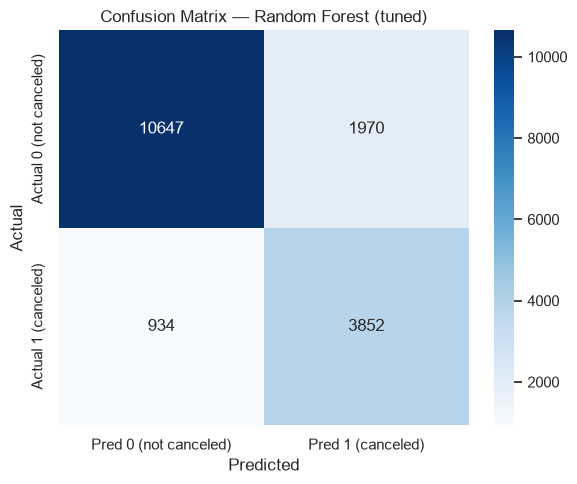

In [67]:
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred 0 (not canceled)", "Pred 1 (canceled)"],
            yticklabels=["Actual 0 (not canceled)", "Actual 1 (canceled)"])
plt.title(f"Confusion Matrix — {best_name}")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.tight_layout()
plt.show()

#  Model Comparison

Final CV comparison table — everything from training-data CV; the test set played no role in choosing the winner.

In [68]:
print(" Final CV comparison (5-fold, training data) — sorted by F1 ")
print(cv_results.to_string(index=False))

print()
print("Baseline for reference ")
print(pd.DataFrame([baseline_row]).round(3).to_string(index=False))

print()
print("Imbalance strategy comparison ")
print(imbalance_cmp.to_string(index=False))

 Final CV comparison (5-fold, training data) — sorted by F1 
              Model  Accuracy  Precision  Recall   F1  ROC-AUC
      Random Forest      84.0       69.3    75.1 72.1     90.3
Logistic Regression      77.6       56.5    80.9 66.6     86.6
         Linear SVC      77.3       56.1    81.2 66.3     86.6
          KNN (k=7)      80.6       66.3    59.8 62.9     84.0
      Decision Tree      79.3       62.2    62.9 62.6     74.2

Baseline for reference 
                Model  Accuracy  Precision  Recall  F1  ROC-AUC
Dummy (most frequent)      72.5        0.0     0.0 0.0     50.0

Imbalance strategy comparison 
       Strategy  Accuracy  Precision  Recall   F1  ROC-AUC
    No handling      81.3       70.6    54.9 61.8     86.7
Class weighting      77.7       56.6    80.9 66.6     86.6
        SMOTENC      78.3       57.9    77.5 66.3     86.2


#  Feature Importance



In [69]:
final_model_step = final_pipeline.named_steps["model"]
final_pre = final_pipeline.named_steps["preprocessor"]
feature_names = final_pre.get_feature_names_out()

print("Final model type:", type(final_model_step).__name__)

if hasattr(final_model_step, "feature_importances_"):
    importance = final_model_step.feature_importances_
    method = "feature_importances_"
elif hasattr(final_model_step, "coef_"):
    importance = np.abs(final_model_step.coef_).ravel()
    method = "|coef|"
else:
    importance = np.zeros(len(feature_names))
    method = "unsupported"

print("Using:", method)
print("Number of importance values:", len(importance))
print("Number of feature names   :", len(feature_names))

Final model type: RandomForestClassifier
Using: feature_importances_
Number of importance values: 120
Number of feature names   : 120


In [70]:
imp_df = pd.DataFrame({"feature": feature_names, "importance": importance})
imp_df = imp_df.sort_values("importance", ascending=False).reset_index(drop=True)

print(f"Top 20 features by {method}:")
print(imp_df.head(20).to_string(index=False))

Top 20 features by feature_importances_:
                      feature  importance
                    lead_time    0.085861
                  country_PRT    0.076125
  required_car_parking_spaces    0.056337
            room_type_changed    0.054936
                          adr    0.054597
     market_segment_Online TA    0.045469
          lead_time_group_0-7    0.035787
    total_of_special_requests    0.034561
     arrival_date_week_number    0.034093
    arrival_date_day_of_month    0.029939
          has_special_request    0.027514
            arrival_date_year    0.026426
 market_segment_Offline TA/TO    0.022812
                 total_nights    0.022288
      customer_type_Transient    0.020839
         stays_in_week_nights    0.019755
              booking_changes    0.019212
   previous_cancellation_rate    0.016171
customer_type_Transient-Party    0.012156
      stays_in_weekend_nights    0.012038


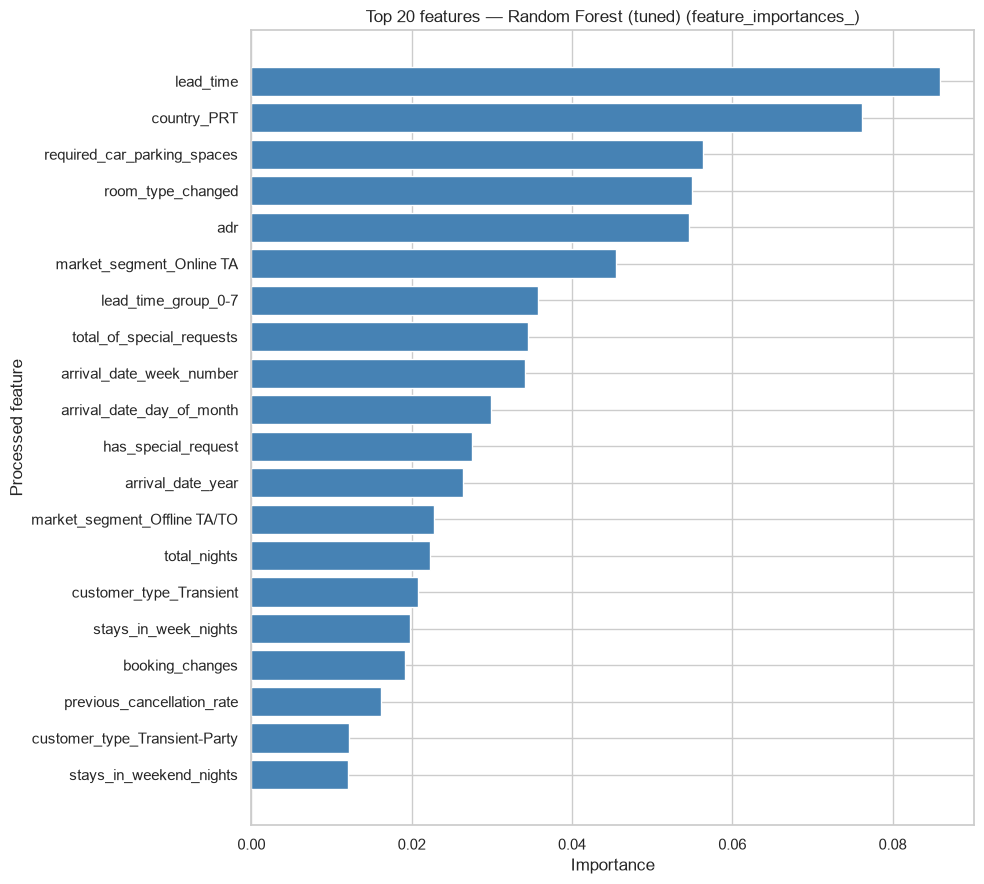

In [71]:
top20 = imp_df.head(20).iloc[::-1]
plt.figure(figsize=(10, 9))
plt.barh(top20["feature"], top20["importance"], color="steelblue")
plt.xlabel("Importance")
plt.ylabel("Processed feature")
plt.title(f"Top 20 features — {best_name} ({method})")
plt.tight_layout()
plt.show()

## PR-AUC and precision-recall metrics

PR-AUC: 0.7944


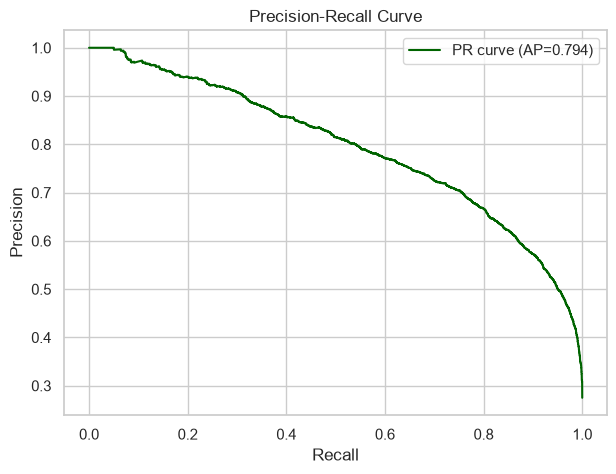

In [74]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, precision_recall_curve,
    confusion_matrix, classification_report
)

y_proba = final_pipeline.predict_proba(X_test)[:, 1]
pr_auc = average_precision_score(y_test, y_proba)

print("PR-AUC:", round(pr_auc, 4))

precision, recall, _ = precision_recall_curve(y_test, y_proba)
plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f"PR curve (AP={pr_auc:.3f})", color="darkgreen")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(True)
plt.show()

In [75]:
def evaluate_thresholds(y_true, y_prob, thresholds=None, fn_cost=5, fp_cost=1):
    if thresholds is None:
        thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

    rows = []
    for t in thresholds:
        pred = (y_prob >= t).astype(int)
        tp = ((pred == 1) & (y_true == 1)).sum()
        tn = ((pred == 0) & (y_true == 0)).sum()
        fp = ((pred == 1) & (y_true == 0)).sum()
        fn = ((pred == 0) & (y_true == 1)).sum()

        accuracy = (tp + tn) / len(y_true)
        precision = tp / (tp + fp) if (tp + fp) else 0
        recall = tp / (tp + fn) if (tp + fn) else 0
        f1 = (2 * precision * recall) / (precision + recall) if (precision + recall) else 0

        cost = fp * fp_cost + fn * fn_cost

        rows.append({
            "threshold": t,
            "accuracy": accuracy,
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "false_positive": fp,
            "false_negative": fn,
            "cost": cost,
        })

    return pd.DataFrame(rows)

threshold_df = evaluate_thresholds(y_test, y_proba)
print(threshold_df.round(4).to_string(index=False))

 threshold  accuracy  precision  recall     f1  false_positive  false_negative  cost
       0.3    0.7348     0.5096  0.9459 0.6624            4356             259  5651
       0.4    0.7934     0.5812  0.8903 0.7033            3070             525  5695
       0.5    0.8331     0.6616  0.8048 0.7262            1970             934  6640
       0.6    0.8450     0.7281  0.6966 0.7120            1245            1452  8505
       0.7    0.8386     0.7833  0.5710 0.6605             756            2053 11021


## Error analysis

In [ ]:

# 1. Build the error table and label each error type

err = X_test.copy()
err["y_true"] = y_test.values
err["y_pred"] = y_pred
err["proba"] = y_proba
err["is_error"] = err["y_true"] != err["y_pred"]

err["error_type"] = np.select(
    [
        (err["y_true"] == 0) & (err["y_pred"] == 1),
        (err["y_true"] == 1) & (err["y_pred"] == 0),
        (err["y_true"] == 1) & (err["y_pred"] == 1),
    ],
    ["False alarm (FP)", "Missed cancellation (FN)", "Caught cancellation (TP)"],
    default="Correct keep (TN)"
)

print(" Overall error breakdown (test set)")
breakdown = err["error_type"].value_counts().to_frame("count")
breakdown["share_%"] = (breakdown["count"] / len(err) * 100).round(1)
print(breakdown.to_string())


# 2. Error rate and recall/precision by segment
# Error rate alone can be misleading, so we also show recall and precision

def group_report(col, min_n=200):
    rows = []
    for k, g in err.groupby(col, observed=True):
        if len(g) < min_n:
            continue  # skip tiny groups, their rates are unreliable

        tp = (g["error_type"] == "Caught cancellation (TP)").sum()
        fn = (g["error_type"] == "Missed cancellation (FN)").sum()
        fp = (g["error_type"] == "False alarm (FP)").sum()

        rows.append({
            col: k,
            "n": len(g),
            "cancel_rate": g["y_true"].mean(),
            "error_rate": g["is_error"].mean(),
            "recall": tp / (tp + fn) if (tp + fn) else np.nan,
            "precision": tp / (tp + fp) if (tp + fp) else np.nan,
            "FN": fn,
            "FP": fp,
        })
    return pd.DataFrame(rows).round(3).sort_values("error_rate", ascending=False)


for col in ["market_segment", "hotel", "lead_time_group", "customer_type", "deposit_type"]:
    print(f"\n Errors by {col} (groups with n >= 200) ")
    print(group_report(col).to_string(index=False))


# 3. How confident are the errors?
# Are they borderline mistakes or confident wrong predictions?

near = err["proba"].between(0.4, 0.6)

print("\n Confidence of errors ")
print(f"Errors with probability between 0.4 and 0.6 : "
      f"{(err['is_error'] & near).sum() / err['is_error'].sum():.1%}")

print("Most confident wrong predictions:")
err["confidence_in_wrong_class"] = np.where(err["y_pred"] == 1, err["proba"], 1 - err["proba"])

show_cols = [c for c in ["hotel", "market_segment", "lead_time", "adr", "deposit_type",
                         "customer_type", "y_true", "y_pred", "proba"] if c in err.columns]

print(
    err[err["is_error"]]
    .sort_values("confidence_in_wrong_class", ascending=False)
    .head(8)[show_cols]
    .round(3)
    .to_string()
)




 Overall error breakdown (test set)
                          count  share_%
error_type                              
Correct keep (TN)         10647     61.2
Caught cancellation (TP)   3852     22.1
False alarm (FP)           1970     11.3
Missed cancellation (FN)    934      5.4

 Errors by market_segment (groups with n >= 200) 
market_segment     n  cancel_rate  error_rate  recall  precision  FN   FP
     Online TA 10249        0.357       0.217   0.845      0.651 566 1659
        Direct  2322        0.146       0.122   0.391      0.629 206   78
     Corporate   847        0.115       0.081   0.485      0.712  50   19
 Offline TA/TO  2818        0.140       0.081   0.835      0.668  65  164
        Groups   996        0.270       0.074   0.892      0.842  29   45

 Errors by hotel (groups with n >= 200) 
       hotel     n  cancel_rate  error_rate  recall  precision  FN   FP
  City Hotel 10515        0.302       0.197   0.791      0.641 664 1410
Resort Hotel  6888        0.233      

#  Final Model



In [72]:
print("Final model:", best_name)
print("Test performance (evaluated once):")
print(f"  F1 score : {f1_score(y_test, y_pred)*100:.1f}%")
print(f"  Recall   : {recall_score(y_test, y_pred)*100:.1f}%")
print(f"  ROC-AUC  : {roc_auc_score(y_test, y_proba)*100:.1f}%")

Final model: Random Forest (tuned)
Test performance (evaluated once):
  F1 score : 72.6%
  Recall   : 80.5%
  ROC-AUC  : 90.9%


## Recommendation

The tuned Random Forest model (ROC-AUC 90.9%, PR-AUC 0.794, F1 72.6% on the held-out test set) is strong enough to support a cancellation-risk flagging system at the point of booking, rather than a hard reject/accept decision. Suggested use:

- **Prioritise intervention on high-risk bookings** — long lead-time, Group and Online TA segments, and City Hotel bookings showed the highest cancellation rates in EDA and the strongest model signal. These are good candidates for proactive reconfirmation calls or flexible overbooking policy.
- **Set the decision threshold by business cost, not by default 0.5.** The cost-sensitive analysis (assuming a missed cancellation costs 5× a false alarm) shows a lower threshold reduces total cost (5,651 at 0.3 vs 6,640 at 0.5) at the expense of more false alarms (precision drops from 66.2% to 51.0%, recall rises from 80.5% to 94.6%). The hotel should pick the threshold that matches its real cost of an empty room versus an unnecessary follow-up.
- **Investigate the Non-Refund deposit anomaly** (99.4% cancellation rate) with the hotel's booking-system team before acting on it — it is far more likely to be a data/logging artefact than a genuine pattern, and should not be used to justify policy changes on its own.

## Limitations

- **Weakest exactly where it matters most operationally:** recall drops to ~26% for same-day (0–7 day lead time) bookings versus ~92% for 181+ day bookings. Short-notice cancellations — the hardest to recover from operationally — are the ones the model is least able to catch.
- **Recall also varies by booking channel**, with Direct and Corporate segments underperforming relative to others — the model is not equally reliable across all customer types.
- **Validated with a random split, not a date-based one.** Training and test data are drawn from the same time range, so this doesn't confirm the model would hold up when trained on past bookings and deployed on genuinely future ones (a date-based split was considered but not run).

- **Outliers were kept** (adr up to 5,400; lead_time up to 737 days) since the final model is tree-based and robust to them, but this would need revisiting if a scale-sensitive model (e.g. Logistic Regression, SVM) were deployed instead.
- **Dataset scope is narrow** — bookings are from two specific Portuguese hotels over a fixed historical period, so the model's patterns may not transfer directly to other markets, hotel chains, or more recent booking behaviour without retraining.
- **No booking ID exists**, so the duplicate-record decision (removing exact matches across all columns) rests on statistical reasoning rather than certainty about which rows are true duplicates versus coincidentally identical bookings.

#  Conclusion



In [73]:
print(" PROJECT RESULT SUMMARY ")
print(f"Dataset loaded: {df.shape[0]:,} rows x {df.shape[1]} cols")
print(f"After cleaning : {df_model.shape[0]:,} rows")
print(f"Modeling split: train = {X_train.shape[0]:,}, test = {X_test.shape[0]:,}")
print()
print("Target distribution (training):")
print(round(y_train.value_counts(normalize=True) * 100, 1).to_string())
print()
print("Cross-validation comparison of all models (5-fold, train):")
print(cv_results.to_string(index=False))
print()
print("Final model:", best_name)
print("Final test metrics:")
print(f"  Accuracy : {accuracy_score(y_test, y_pred)*100:.1f}%")
print(f"  Precision: {precision_score(y_test, y_pred)*100:.1f}%")
print(f"  Recall   : {recall_score(y_test, y_pred)*100:.1f}%")
print(f"  F1       : {f1_score(y_test, y_pred)*100:.1f}%")
print(f"  ROC-AUC  : {roc_auc_score(y_test, y_proba)*100:.1f}%")
print()
print("Top 5 features by importance:")
print(imp_df.head(5).to_string(index=False))
print(" END OF SUMMARY ")

 PROJECT RESULT SUMMARY 
Dataset loaded: 119,390 rows x 32 cols
After cleaning : 87,011 rows
Modeling split: train = 69,608, test = 17,403

Target distribution (training):
is_canceled
0    72.5
1    27.5

Cross-validation comparison of all models (5-fold, train):
              Model  Accuracy  Precision  Recall   F1  ROC-AUC
      Random Forest      84.0       69.3    75.1 72.1     90.3
Logistic Regression      77.6       56.5    80.9 66.6     86.6
         Linear SVC      77.3       56.1    81.2 66.3     86.6
          KNN (k=7)      80.6       66.3    59.8 62.9     84.0
      Decision Tree      79.3       62.2    62.9 62.6     74.2

Final model: Random Forest (tuned)
Final test metrics:
  Accuracy : 83.3%
  Precision: 66.2%
  Recall   : 80.5%
  F1       : 72.6%
  ROC-AUC  : 90.9%

Top 5 features by importance:
                    feature  importance
                  lead_time    0.085861
                country_PRT    0.076125
required_car_parking_spaces    0.056337
          room_t